In [242]:
import os
import sys
import time
import math
import argparse
from dataclasses import dataclass
from typing import List

import torch
import torch.nn as nn
from torch.nn import functional as F

import torch.nn.init as init
from torch.utils.data import Dataset
from torch.utils.data.dataloader import DataLoader
import matplotlib.pyplot as plt

In [3]:
with open('names.txt', 'r') as f:
    names = f.readlines()

In [4]:
names = [x.strip() for x in names] 

In [5]:
chars = sorted(list(set([c for x in names for c in x])))
chars

['a',
 'b',
 'c',
 'd',
 'e',
 'f',
 'g',
 'h',
 'i',
 'j',
 'k',
 'l',
 'm',
 'n',
 'o',
 'p',
 'q',
 'r',
 's',
 't',
 'u',
 'v',
 'w',
 'x',
 'y',
 'z']

In [6]:
words = names

In [7]:
class CharDataset(Dataset):
    def __init__(self, words, chars, max_word_length):
        self.words = words
        self.chars = chars
        self.max_word_length = max_word_length
        self.stoi = {ch:i+1 for i,ch in enumerate(chars)} # '.' is 0
        self.itos = {i:s for s,i in self.stoi.items()} # inverse mapping

    def __len__(self):
        return len(self.words)

    def contains(self, word):
        return word in self.words

    def get_vocab_size(self):
        return len(self.chars) + 1 # all the possible characters and special 0 token

    def get_output_length(self):
        return self.max_word_length + 1 # <START> token followed by words

    def encode(self, word):
        ix = torch.tensor([self.stoi[w] for w in word], dtype=torch.long)
        return ix

    def decode(self, ix):
        word = ''.join(self.itos[i] for i in ix)
        return word
    
    def __getitem__(self, idx):
        word = self.words[idx]
        ix = self.encode(word)

        x = torch.zeros(self.max_word_length+1, dtype=torch.long)
        y = torch.zeros(self.max_word_length+1, dtype=torch.long)

        x[1:1+len(ix)] = ix
        y[:len(ix)] = ix
        y[len(ix)+1:] = -1 # index -1 will mask the loss at the inactive locations

        return x,y





In [27]:
max_word_length = max([len(w) for w in words])

# partition the input data into a training and the test set
test_set_size = min(1000, int(len(words) * 0.1)) # 10% of the training set, or up to 1000 examples
rp = torch.randperm(len(words)).tolist()
train_words = [words[i] for i in rp[:-test_set_size]]
test_words = [words[i] for i in rp[-test_set_size:]]
print(f"split up the dataset into {len(train_words)} training examples and {len(test_words)} test examples")

# wrap in dataset objects
train_dataset = CharDataset(train_words, chars, max_word_length)
test_dataset = CharDataset(test_words, chars, max_word_length)

   

split up the dataset into 31033 training examples and 1000 test examples


In [9]:
train_dataset[0]

(tensor([ 0, 19,  1, 18,  9, 25,  1,  0,  0,  0,  0,  0,  0,  0,  0,  0]),
 tensor([19,  1, 18,  9, 25,  1,  0, -1, -1, -1, -1, -1, -1, -1, -1, -1]))

In [28]:
class InfiniteDataLoader:
    """
    this is really hacky and I'm not proud of it, but there doesn't seem to be
    a better way in PyTorch to just create an infinite dataloader?
    """

    def __init__(self, dataset, **kwargs):
        train_sampler = torch.utils.data.RandomSampler(dataset, replacement=True, num_samples=int(1e10))
        self.train_loader = DataLoader(dataset, sampler=train_sampler, **kwargs)
        self.data_iter = iter(self.train_loader)

    def next(self):
        try:
            batch = next(self.data_iter)
        except StopIteration: # this will technically only happen after 1e10 samples... (i.e. basically never)
            self.data_iter = iter(self.train_loader)
            batch = next(self.data_iter)
        return batch

In [112]:
# init dataloader
batch_loader = InfiniteDataLoader(train_dataset, batch_size=128, pin_memory=True, num_workers=4)

In [12]:
batch = batch_loader.next()

In [ ]:
@dataclass
class Config:
    block_size:int = None
    vocab_size:int = None
    n_layer:int = 4
    n_embd:int = 64
    n_embd2:int = 64 
    n_head:int = 4

class Bigram(nn.Module):
    def __init__(self, config:Config):
        super().__init__()
        self.W = nn.Parameter(torch.zeros((config.vocab_size, config.vocab_size)))

    def get_block_size(self):
        return 1
    
    def forward(self, x, targets=None):

        logit = self.W[x]
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logit.view(-1, logit.size(-1)), targets.view(-1), ignore_index=-1)
        return logit, loss

class MLP(nn.Module):
    def __init__(self, config:Config):
        super().__init__()
        self.n_embd=config.n_embd
        self.n_embd2 = config.n_embd2
        self.block_size = config.block_size
        self.vocab_size = config.vocab_size
        self.embd = nn.Embedding(config.vocab_size+1, config.n_embd)
        self.mlp =  nn.Sequential(nn.Linear(self.block_size * config.n_embd, config.n_embd2), 
                                  nn.Tanh( ),
                                  nn.Linear(config.n_embd2, config.vocab_size)
        )

        init.kaiming_normal_(self.mlp[0].weight, nonlinearity='tanh')
        init.kaiming_normal_(self.mlp[2].weight, nonlinearity='linear')

    

    def get_block_size(self):
        return self.block_size

    def forward(self, x, targets=None):

        # important do not pad zero here. Need to pad special token.
        # padded = torch.cat([torch.zeros(x.shape[0], self.block_size-1, self.n_embd), emb], dim=1)#.shape # B*(T+3)*C
        # print(x.shape)
        padding = torch.full((x.shape[0], self.block_size - 1), self.vocab_size, dtype=x.dtype, device=x.device)
        padded = torch.cat([padding, x], dim=1)#.shape # B*(T+3)*C

        flattened = padded.unfold(1, self.block_size, 1)
        # print(flattened.shape)


        # always do idx operations first, so that we are doing clean!!
        emb = self.embd(flattened) # B * (T+3) * C


        # print(emb.shape)


        emb = emb.contiguous().view(x.shape[0], x.shape[1], -1) # B * (T)* (3 * C)

        logit = self.mlp(emb) # B * 
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logit.view(-1, logit.size(-1)), targets.view(-1), ignore_index=-1)
        return logit, loss


In [241]:
x = torch.randn(2000,100)
w = torch.randn(100,20)/100**0.5
x.std(), w.std(), (x@w).std()

(tensor(0.9977), tensor(0.1026), tensor(1.0265))

In [230]:
model = MLP(config).cuda()
handles = []
activations = {}
def forward_value_hook(name):
    def hook(module, inputs, output):
        activations.setdefault(name, []).append(
            output.detach().float().cpu().flatten()
        )
    return hook

def forward_hook(module, inputs, output):
    print(module.__class__.__name__,
          "min:", output.detach().min().item(),
          "max:", output.detach().max().item(),
        "mean:", output.detach().mean().item(),
        "std:", output.detach().std().item())

def backward_hook(module, grad_input, grad_output):
    g = grad_output[0]
    if g is not None:
        print(module.__class__.__name__,
            "grad RMS:", g.detach().square().mean().sqrt().item())


for name, layer in model.mlp.named_modules():
    handles.append(layer.register_forward_hook(forward_value_hook(name)))
    handles.append(layer.register_full_backward_hook(backward_hook))
logit, loss = model(x, y)

(array([  27.,   64.,  120.,  162.,  186.,  287.,  329.,  359.,  440.,
         496.,  506.,  646.,  845.,  779.,  781.,  971., 1000.,  936.,
        1015., 1057., 1104., 1192., 1246., 1215., 1223., 1358., 1396.,
        1357., 1386., 1567., 1481., 1591., 1751., 1602., 1630., 1999.,
        1965., 1738., 1921., 1802., 1777., 1879., 1865., 1690., 1925.,
        1831., 1978., 1819., 2275., 1724., 1803., 1828., 2297., 1856.,
        1736., 1821., 1901., 1779., 1821., 1807., 1754., 2017., 1735.,
        1898., 1982., 1741., 1767., 1740., 1872., 1535., 1688., 1628.,
        1705., 1902., 1447., 1684., 1646., 1500., 1464., 1619., 1461.,
        1426., 1572., 1559., 1352., 1272., 1498., 1112., 1067.,  964.,
         929.,  754.,  733.,  557.,  520.,  343.,  278.,  281.,   94.,
          34.]),
 array([-0.98270923, -0.96314716, -0.9435851 , -0.92402303, -0.90446103,
        -0.88489896, -0.86533689, -0.84577483, -0.82621276, -0.80665076,
        -0.78708863, -0.76752663, -0.74796456, -0.728402

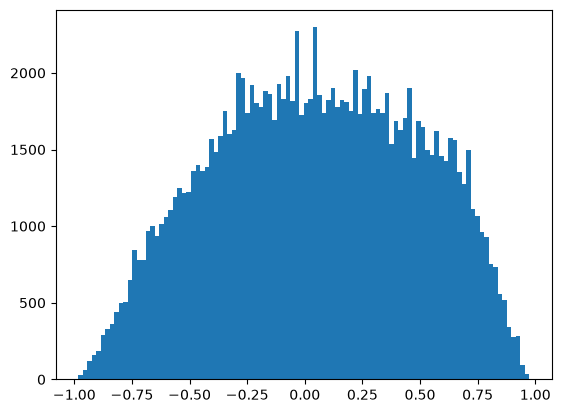

In [235]:
plt.hist(activations['1'], bins=100)

In [220]:
loss.backward()

Linear grad RMS: 0.0001392474805470556
Tanh grad RMS: 5.229975067777559e-05
Linear grad RMS: 4.250507481629029e-05


In [31]:
vocab_size = train_dataset.get_vocab_size()
block_size = train_dataset.get_output_length()
print(f"dataset determined that: {vocab_size=}, {block_size=}")

dataset determined that: vocab_size=27, block_size=16


In [32]:
config = Config(vocab_size=vocab_size, block_size=block_size,
                       n_layer=2, n_head=4,
                       n_embd=64, n_embd2=64)

In [33]:
model = Bigram(config)
model.to('cuda')

Bigram()

In [121]:
optimizer = torch.optim.AdamW(model.parameters(), lr=0.1, weight_decay=0.01, betas=(0.9,0.999), eps=1e-8)

In [35]:
@torch.inference_mode()
def evaluate(model, dataset, batch_size=100, max_batches=10 ):
    model.eval()
    loader = DataLoader(dataset, shuffle=True, batch_size=batch_size, num_workers=0)
    losses = []
    for i, batch in enumerate(loader):
        batch = [t.to('cuda') for t in batch]
        X, Y = batch
        logits, loss = model(X, Y)
        losses.append(loss.item())
        if max_batches is not None and i >= max_batches:
            break
    mean_loss = torch.tensor(losses).mean().item()
    model.train() # reset model back to training mode
    return mean_loss

In [38]:
@torch.no_grad()
def generate(model, idx, max_new_tokens, temperature=1.0, do_sample=False, top_k=None):
    """
    Take a conditioning sequence of indices idx (LongTensor of shape (b,t)) and complete
    the sequence max_new_tokens times, feeding the predictions back into the model each time.
    Most likely you'll want to make sure to be in model.eval() mode of operation for this.
    """
    block_size = model.get_block_size()
    for _ in range(max_new_tokens):
        # if the sequence context is growing too long we must crop it at block_size
        idx_cond = idx if idx.size(1) <= block_size else idx[:, -block_size:]
        # forward the model to get the logits for the index in the sequence
        logits, _ = model(idx_cond)
        # pluck the logits at the final step and scale by desired temperature
        logits = logits[:, -1, :] / temperature
        # optionally crop the logits to only the top k options
        if top_k is not None:
            v, _ = torch.topk(logits, top_k)
            logits[logits < v[:, [-1]]] = -float('Inf')
        # apply softmax to convert logits to (normalized) probabilities
        probs = F.softmax(logits, dim=-1)
        # either sample from the distribution or take the most likely element
        if do_sample:
            idx_next = torch.multinomial(probs, num_samples=1)
        else:
            _, idx_next = torch.topk(probs, k=1, dim=-1)
        # append sampled index to the running sequence and continue
        idx = torch.cat((idx, idx_next), dim=1)

    return idx

def print_samples(num=10):
    """ samples from the model and pretty prints the decoded samples """
    X_init = torch.zeros(num, 1, dtype=torch.long).to('cuda')
    top_k = None
    steps = train_dataset.get_output_length() - 1 # -1 because we already start with <START> token (index 0)
    X_samp = generate(model, X_init, steps, top_k=top_k, do_sample=True).to('cpu')
    train_samples, test_samples, new_samples = [], [], []
    for i in range(X_samp.size(0)):
        # get the i'th row of sampled integers, as python list
        row = X_samp[i, 1:].tolist() # note: we need to crop out the first <START> token
        # token 0 is the <STOP> token, so we crop the output sequence at that point
        crop_index = row.index(0) if 0 in row else len(row)
        row = row[:crop_index]
        word_samp = train_dataset.decode(row)
        # separately track samples that we have and have not seen before
        if train_dataset.contains(word_samp):
            train_samples.append(word_samp)
        elif test_dataset.contains(word_samp):
            test_samples.append(word_samp)
        else:
            new_samples.append(word_samp)
    print('-'*80)
    for lst, desc in [(train_samples, 'in train'), (test_samples, 'in test'), (new_samples, 'new')]:
        print(f"{len(lst)} samples that are {desc}:")
        for word in lst:
            print(word)
    print('-'*80)

In [204]:
losses = []
lrs = []
lr_schedule = torch.pow(10, torch.linspace(-4,-1,steps=1000))
# lr_schedule

In [208]:
best_loss = 0 
step = 0

model = MLP(config).cuda()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=0.01, betas=(0.9,0.999), eps=1e-8)


while step <5000:
    t0=time.time()

    batch = batch_loader.next()
    batch = [t.to(torch.device('cuda')) for t in batch]
    X, Y = batch
    logit, loss = model(X, Y)

    model.zero_grad(set_to_none=True)
    
    loss.backward()
    # lri = lr_schedule[step]
    # for param_group in optimizer.param_groups:
    #     param_group['lr'] = lri
    losses.append(loss.item())
    # lrs.append(lri)
    optimizer.step()

    # wait for all CUDA work on the GPU to finish then calculate iteration time taken
    torch.cuda.synchronize()
    t1 = time.time()

    if step % 100 == 0:
        print(f"step {step} | loss {loss.item():.4f} | step time {(t1-t0)*1000:.2f}ms")


    if step > 0 and step % 500 == 0:
        train_loss = evaluate(model, train_dataset, batch_size=100, max_batches=10)
        test_loss  = evaluate(model, test_dataset,  batch_size=100, max_batches=10)
        
        print(f"step {step} train loss: {train_loss} test loss: {test_loss}")
        # save the model to disk if it has improved
        if best_loss is None or test_loss < best_loss:
            out_path = os.path.join('/home/dding/workspace/LLM/src/micrograd/out', "model.pt")
            print(f"test loss {test_loss} is the best so far, saving model to {out_path}")
            torch.save(model.state_dict(), out_path)
            best_loss = test_loss

    # sample from the model
    if step > 0 and step % 200 == 0:
        print_samples(num=10)

    step += 1
    # break



step 0 | loss 3.2530 | step time 62.32ms
step 100 | loss 2.3868 | step time 3.02ms
step 200 | loss 2.2913 | step time 2.70ms
--------------------------------------------------------------------------------
0 samples that are in train:
0 samples that are in test:
10 samples that are new:
raleelh
gerri
griura
iska
crasanl
srenioha
pamiur
haghen
irino
hayny
--------------------------------------------------------------------------------
step 300 | loss 2.2326 | step time 2.86ms
step 400 | loss 2.1570 | step time 3.50ms
--------------------------------------------------------------------------------
0 samples that are in train:
0 samples that are in test:
10 samples that are new:
jarna
dyvina
kemeis
alsinke
pipjia
jayshahh
kamlees
laxhyn
naryii
cekyn
--------------------------------------------------------------------------------
step 500 | loss 2.1910 | step time 3.02ms
step 500 train loss: 2.1941936016082764 test loss: 2.2057442665100098
step 600 | loss 2.1927 | step time 2.76ms
--------

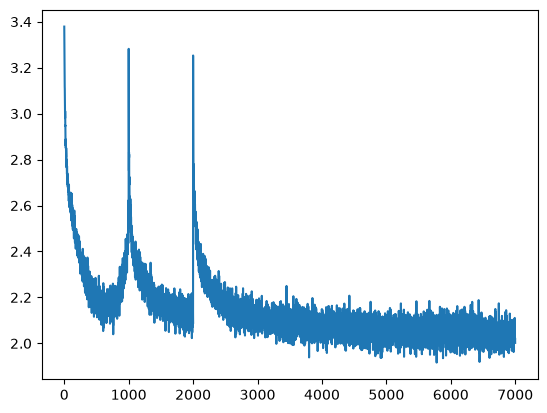

In [209]:
plt.plot(losses)

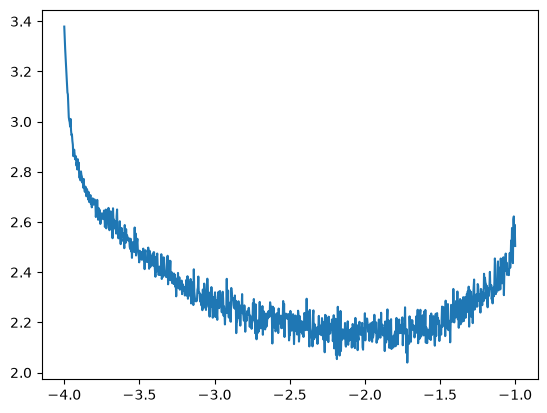

In [206]:

# plt.plot(torch.log10(torch.tensor(lrs)), torch.log10(torch.tensor(losses)))
plt.plot(torch.log10(torch.tensor(lrs)), torch.tensor(losses))

In [190]:
torch.log10(torch.tensor(lrs))

tensor([-5.0000, -4.9950, -4.9900, -4.9850, -4.9800, -4.9750, -4.9700, -4.9650,
        -4.9600, -4.9550, -4.9499, -4.9449, -4.9399, -4.9349, -4.9299, -4.9249,
        -4.9199, -4.9149, -4.9099, -4.9049, -4.8999, -4.8949, -4.8899, -4.8849,
        -4.8799, -4.8749, -4.8699, -4.8649, -4.8599, -4.8549, -4.8498, -4.8448,
        -4.8398, -4.8348, -4.8298, -4.8248, -4.8198, -4.8148, -4.8098, -4.8048,
        -4.7998, -4.7948, -4.7898, -4.7848, -4.7798, -4.7748, -4.7698, -4.7648,
        -4.7598, -4.7548, -4.7497, -4.7447, -4.7397, -4.7347, -4.7297, -4.7247,
        -4.7197, -4.7147, -4.7097, -4.7047, -4.6997, -4.6947, -4.6897, -4.6847,
        -4.6797, -4.6747, -4.6697, -4.6647, -4.6597, -4.6547, -4.6496, -4.6446,
        -4.6396, -4.6346, -4.6296, -4.6246, -4.6196, -4.6146, -4.6096, -4.6046,
        -4.5996, -4.5946, -4.5896, -4.5846, -4.5796, -4.5746, -4.5696, -4.5646,
        -4.5596, -4.5546, -4.5495, -4.5445, -4.5395, -4.5345, -4.5295, -4.5245,
        -4.5195, -4.5145, -4.5095, -4.50